# 07 · Anomaly investigation (optional extension)
**Question:** can unusual operational hours be found from the data alone, without the incident log?

This is **not** fraud detection, and there are no fraud labels. The unit is a **channel-hour**: attempts, operational failure rate and 95th-percentile latency. An Isolation Forest flags hours that look unlike the rest. The incident log is used only *afterwards*, to see what the model found.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.max_columns", 30)
engine = get_engine()
o = an.sql_output

In [2]:
from sklearn.ensemble import IsolationForest
ch = query(engine, "SELECT * FROM bank.mv_channel_hour")
ch['hour_ts'] = pd.to_datetime(ch.hour_ts)
# expected attempts for this channel, weekday and hour (median over the window)
ch['expected'] = ch.groupby(['channel', 'iso_dow', 'hour_of_day']).attempts.transform('median')
busy = ch.expected >= 10           # skip hours that are normally almost empty (e.g. agents at 3 a.m.)
d = ch[busy].copy()
d['volume_ratio'] = np.log1p(d.attempts) - np.log1p(d.expected)
d['op_fail_rate'] = (d.operational_failures + 0.5) / (d.attempts + 30)      # smoothed so quiet hours don't dominate
d['latency_ratio'] = np.log(d.p95_ms.fillna(d.groupby('channel').p95_ms.transform('median')) / d.groupby('channel').p95_ms.transform('median'))
feats = ['volume_ratio', 'op_fail_rate', 'latency_ratio']
# standardise within channel so each channel is judged against its own normal
Z = d.groupby('channel')[feats].transform(lambda s: (s - s.median()) / (s.quantile(.75) - s.quantile(.25) + 1e-9))
iso = IsolationForest(n_estimators=300, contamination=0.003, random_state=7).fit(Z)
d['score'] = -iso.score_samples(Z); d['flag'] = iso.predict(Z) == -1
print(f"channel-hours scored: {len(d):,}; flagged: {d.flag.sum()}")

channel-hours scored: 54,046; flagged: 163


Flagged hours that are next to each other on the same channel are grouped into **episodes**.

In [3]:
f = d[d.flag].sort_values(['channel', 'hour_ts'])
f['episode'] = (f.groupby('channel').hour_ts.diff() != pd.Timedelta(hours=1)).cumsum()
ep = f.groupby('episode').agg(channel=('channel', 'first'), start=('hour_ts', 'min'), end=('hour_ts', 'max'),
                              hours=('hour_ts', 'size'), attempts=('attempts', 'sum'), op_failures=('operational_failures', 'sum'),
                              max_score=('score', 'max')).reset_index(drop=True)
ep['op_fail_pct'] = (100 * ep.op_failures / ep.attempts).round(1)
inc = query(engine, "SELECT * FROM bank.system_incidents")
def match(r):
    m = inc[(inc.channel == r.channel) & (pd.to_datetime(inc.start_ts) <= r.end + pd.Timedelta(hours=1)) & (pd.to_datetime(inc.end_ts) >= r.start)]
    return m.incident_id.iloc[0] if len(m) else None
ep['logged_incident'] = ep.apply(match, axis=1)
ep.sort_values('max_score', ascending=False).head(25)

,channel,start,end,hours,attempts,op_failures,max_score,op_fail_pct,logged_incident
66,Mobile App,2025-06-14 19:00:00,2025-06-14 21:00:00,3,275,144,0.81,52.40,INC-001
50,Agent,2026-06-30 09:00:00,2026-06-30 15:00:00,7,433,232,0.80,53.60,INC-011
26,ATM,2025-11-30 07:00:00,2025-11-30 14:00:00,8,234,119,0.80,50.90,INC-006
80,Mobile App,2026-08-21 20:00:00,2026-08-21 21:00:00,2,311,173,0.80,55.60,INC-012
69,Mobile App,2025-10-24 20:00:00,2025-10-24 21:00:00,2,214,121,0.80,56.50,NaN
74,Mobile App,2026-03-13 18:00:00,2026-03-13 20:00:00,3,486,303,0.80,62.30,INC-009
60,Internet Banking,2026-09-04 14:00:00,2026-09-04 16:00:00,3,99,58,0.79,58.60,NaN
25,ATM,2025-11-07 21:00:00,2025-11-07 21:00:00,1,6,1,0.79,16.70,NaN
49,Agent,2025-08-29 10:00:00,2025-08-29 15:00:00,6,276,151,0.79,54.70,INC-003
31,ATM,2025-12-29 21:00:00,2025-12-29 21:00:00,1,20,3,0.78,15.00,NaN


In [4]:
logged_found = ep.logged_incident.dropna().nunique()
print(f"Logged incidents: {len(inc)}; found by the model: {logged_found}")
unlogged = ep[ep.logged_incident.isna() & (ep.op_fail_pct >= 20) & (ep.op_failures >= 15)]
print("Episodes with at least 15 operational failures and a 20%+ failure rate that are NOT in the incident log:")
unlogged[['channel', 'start', 'end', 'hours', 'attempts', 'op_fail_pct']]

Logged incidents: 11; found by the model: 11
Episodes with at least 15 operational failures and a 20%+ failure rate that are NOT in the incident log:


,channel,start,end,hours,attempts,op_fail_pct
60,Internet Banking,2026-09-04 14:00:00,2026-09-04 16:00:00,3,99,58.60
69,Mobile App,2025-10-24 20:00:00,2025-10-24 21:00:00,2,214,56.50
84,USSD,2026-05-29 19:00:00,2026-05-29 21:00:00,3,192,63.00


**What the model found.** It recovers all 11 logged incidents from the data alone. It also flags **three high-failure episodes that are not in the incident log** (an app outage in October 2025, a USSD outage in May 2026 and an Internet Banking outage in September 2026). These are the most useful output: outages that customers felt but nobody recorded, so they were never reviewed. The remaining flags are mostly unusually busy or quiet hours with normal failure rates (for example public-holiday patterns), which are worth a glance but not an escalation.

*Validation (possible only because the data is synthetic):* the generator kept a private list of every outage it injected, including three that were deliberately left out of the log.

In [5]:
truth = pd.read_csv(PROJECT_ROOT / 'data/synthetic/raw/_truth_incidents.csv'); truth['start'] = pd.to_datetime(truth.start)
truth['end'] = truth.start + pd.to_timedelta(truth.hours, unit='h')
truth['found_by_model'] = truth.apply(lambda t: bool(((ep.channel == t.channel) & (ep.start <= t.end) & (ep.end >= t.start)).any()), axis=1)
truth

,channel,start,hours,logged,end,found_by_model
0,Mobile App,2025-06-14 19:00:00,3,True,2025-06-14 22:00:00,True
1,USSD,2025-07-31 18:00:00,4,True,2025-07-31 22:00:00,True
2,Agent,2025-08-29 10:00:00,6,True,2025-08-29 16:00:00,True
3,Internet Banking,2025-09-15 09:00:00,2,True,2025-09-15 11:00:00,True
4,Mobile App,2025-10-24 20:00:00,2,False,2025-10-24 22:00:00,True
5,ATM,2025-11-30 07:00:00,8,True,2025-11-30 15:00:00,True
6,USSD,2025-12-23 17:00:00,5,True,2025-12-23 22:00:00,True
7,Wallet Link,2026-01-12 11:00:00,4,True,2026-01-12 15:00:00,True
8,Mobile App,2026-03-13 18:00:00,3,True,2026-03-13 21:00:00,True
9,USSD,2026-05-29 19:00:00,3,False,2026-05-29 22:00:00,True


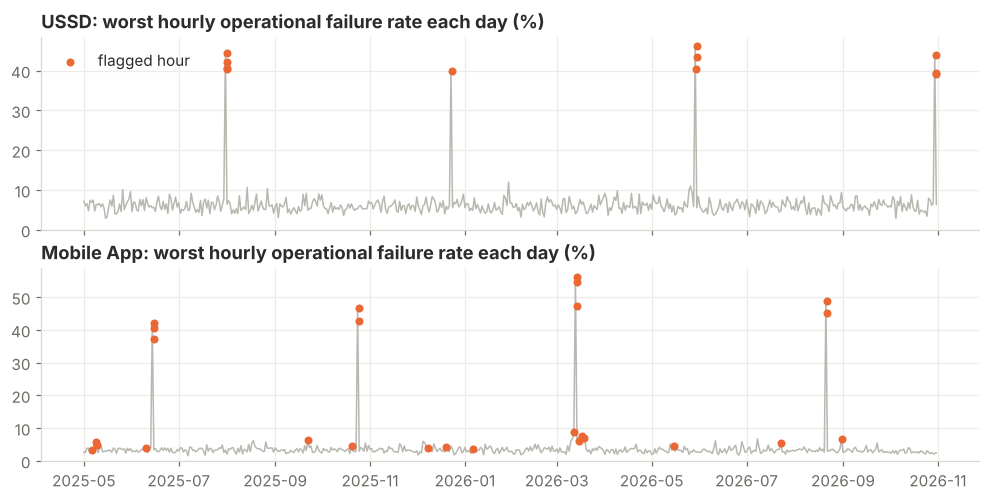

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for ax, c in zip(axes, ['USSD', 'Mobile App']):
    s = d[d.channel == c].set_index('hour_ts').op_fail_rate.resample('D').max() * 100
    ax.plot(s.index, s.values, color=an.CONTEXT, lw=1)
    fl = d[(d.channel == c) & d.flag]
    ax.scatter(fl.hour_ts, 100 * fl.op_fail_rate, color=an.HIGHLIGHT, s=18, zorder=3, label='flagged hour')
    ax.set_title(f"{c}: worst hourly operational failure rate each day (%)"); ax.set_ylim(0)
axes[0].legend(loc='upper left'); an.save(fig, "anomaly_timeline");

**Limits.** A slow-burning problem is harder to see hour by hour: the March 2026 app release raised timeouts to 3–4% for ten days, which barely moves a single hour, but the daily view in notebook 04 shows it clearly. Hourly anomaly detection and daily trend monitoring are complementary. Isolation Forest also has no notion of cause and a contamination rate that I chose (0.3% of hours). With real data, flagged hours would go to the operations team for review, and their feedback (real incident or not) would tune the threshold. It is a monitoring aid, not an alarm system.